# 05 — Ensemble Model Training (untuned)

This notebook trains the ensemble models with **standard starting settings** (tuning follows in notebook 06) on exactly
the same features, split, folds and metrics as the baselines in notebook 04. Errors are in **kWh per household-month**.

Contents: 1 How each algorithm works · 2 Results · 3 Over-fitting check · 4 Voting · 5 Time-ordered stacking ·
6 Summary

## 1. How each algorithm works

### Bagging — many independent trees, averaged

**Decision tree.** Asks yes/no questions about the features, e.g. *"Was last month's bill above 150 kWh?" → "Was the
3-month average above 140 kWh?" → predict 162 kWh.* One deep tree memorises noise (high variance).

**Random Forest (bagging).** Grows many trees, each on a **bootstrap sample** (random rows drawn with replacement) and
considering a **random subset of features** at each split, then **averages** them. Imagine 200 LECO meter readers each
estimating a household's next bill from a slightly different set of past households: individual estimates are noisy,
but their average is stable. Averaging reduces variance without increasing bias much.
*Key settings:* `n_estimators` (number of trees), `max_depth`, `min_samples_leaf` (minimum households per leaf),
`max_features` (features considered per split). *Pros:* robust, little tuning, handles non-linearity and interactions.
*Cons:* large models in memory, cannot extrapolate beyond training values. *Cost:* trees train in parallel.
*Over-fitting:* individual trees over-fit; averaging controls it, larger leaves reduce it further.

**Extra Trees (extremely randomised trees).** Like a Random Forest, but split thresholds are chosen **at random** and
(by default) the full dataset is used for every tree. More randomness → even lower variance, faster training,
sometimes slightly higher bias. Included as a second bagging-style model to see whether extra randomisation helps.

### Boosting — trees built one after another, each correcting the previous errors

**Gradient Boosting.** Starts with a simple prediction (e.g. the average bill), then adds **small trees one at a time**;
each new tree is trained on the **remaining errors (residuals)** of the model so far. Example: the first trees learn
"high last bill → high prediction"; later trees learn corrections such as "but households with a recent big drop are
over-predicted by ~20 kWh". A **learning rate** shrinks each tree's contribution so that the model improves gradually.
*Key settings:* `n_estimators`, `learning_rate`, `max_depth`, `subsample`. *Pros:* often the most accurate on tabular
data. *Cons:* sequential (slower), more sensitive to settings, can over-fit if too many/too deep trees.

**XGBoost.** An optimised gradient-boosting library: second-order (Newton) updates, built-in L1/L2 regularisation of
leaf values (`reg_lambda`), column sampling, histogram-based fast training. **HistGradientBoosting** is sklearn's
similar fast, histogram-based implementation (included as an optional extra).

### Combining different models

**Voting.** Trains several different models and **averages** their predictions. Works when the members make *different*
mistakes.

**Stacking.** Instead of a plain average, a **meta-learner** learns *how much to trust each base model* from their
out-of-fold predictions (section 5).

### Why these models suit household electricity data

Bills depend on the household's own history in **non-linear** ways (stable households vs households that just changed
level, zeros, missing months), and on **interactions** (a recent drop means something different for a 50 kWh household
than for a 500 kWh one). Tree ensembles capture these automatically, are insensitive to feature scale, and handle the
skewed distribution better than a single linear equation.

### Starting settings used here (untuned)

| Model | Settings | Note |
|---|---|---|
| Random Forest | 200 trees, `min_samples_leaf=5` | sklearn's default (leaf = 1) needs ≈1.7 GB on this data — not feasible on a laptop |
| Extra Trees | 200 trees, `min_samples_leaf=5` | default needs ≈2.8 GB |
| Gradient Boosting | sklearn defaults (100 trees, depth 3, learning rate 0.1) | |
| XGBoost | library defaults (100 trees, depth 6, learning rate 0.3) | |
| HistGradientBoosting | sklearn defaults | |
| Voting | average of RF, Extra Trees, Gradient Boosting | the three best individual untuned models (validation MAE) |
| Stacking | naive persistence + Ridge + Extra Trees + Gradient Boosting → Ridge meta-learner | diverse base learners |

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plot_style as ps
from src.data_loader import CONSUMPTION_UNIT as U
from src.models import make_pipeline, MODEL_INFO
from src.train import load_modelling_data, run_model, load_summaries, load_test_predictions, load_cv
from src.evaluate import regression_metrics, per_month_metrics
ps.apply(); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
F, train, test = load_modelling_data()
print(f"Training rows: {len(train):,} ({train.month.min():%Y-%m}…{train.month.max():%Y-%m}) | "
      f"test rows: {len(test):,} ({test.month.min():%Y-%m}…{test.month.max():%Y-%m}) | unit: {U}")

Training rows: 68,485 (2023-01…2024-05) | test rows: 20,094 (2024-06…2024-10) | unit: kWh


In [2]:
from src.models import make_voting
from src.ensembles import TimeOrderedStackingRegressor
from src.train import run_stacking, EXPERIMENTS
RERUN = False   # set True to retrain everything (≈ 12 minutes on a 12-core laptop)
def need(label): return RERUN or not (EXPERIMENTS / f"summary__untuned__{label}__history_only.json").exists()

for k in ["random_forest", "extra_trees", "gradient_boosting", "xgboost", "hist_gradient_boosting"]:
    if need(k): run_model(k, make_pipeline(k), experiment="untuned", label=k)
if need("voting"):
    run_model("voting", make_voting({"random_forest": {}, "extra_trees": {}, "gradient_boosting": {}}), experiment="untuned", label="voting")
if need("stacking"):
    bases = {"naive_last_month": make_pipeline("naive_last_month"), "ridge": make_pipeline("ridge", params={"alpha": 1000}),
             "extra_trees": make_pipeline("extra_trees"), "gradient_boosting": make_pipeline("gradient_boosting")}
    run_stacking(TimeOrderedStackingRegressor(bases), experiment="untuned", label="stacking")
print("Saved results are in", EXPERIMENTS.relative_to(ROOT))

Saved results are in artifacts\experiments


## 2. Results — ensembles vs baselines (same split, same folds)

In [3]:
res = pd.concat([load_summaries("main"), load_summaries("untuned")]).set_index("label")
cols = ["family", "cv_MAE", "cv_MAE_std", "cv_RMSE", "cv_R2", "test_MAE", "test_RMSE", "test_R2", "train_MAE", "fit_seconds_full"]
table = res[cols].sort_values("cv_MAE")
table.round(3)

,family,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,test_MAE,test_RMSE,test_R2,train_MAE,fit_seconds_full
label,,,,,,,,,,
stacking,Ensemble combination,19.066,2.687,42.267,0.893,19.670,43.636,0.889,15.829,167.965
voting,Ensemble combination,19.105,2.558,42.255,0.893,19.757,43.712,0.889,13.567,47.924
extra_trees,Bagging,19.242,2.376,42.800,0.891,20.042,44.003,0.887,12.340,9.766
gradient_boosting,Boosting,19.408,2.893,42.577,0.892,19.997,44.332,0.886,17.396,18.333
random_forest,Bagging,19.429,2.466,42.748,0.891,20.024,44.338,0.886,11.629,21.535
hist_gradient_boosting,Boosting,19.690,2.130,46.500,0.870,20.861,49.642,0.857,17.402,0.540
naive_last_month,Baseline,19.695,2.484,47.836,0.861,19.491,48.843,0.861,18.969,0.001
xgboost,Boosting,20.585,2.069,53.677,0.827,21.926,52.920,0.837,14.348,0.537
ridge,Baseline,20.806,3.546,45.014,0.879,19.889,43.414,0.890,18.409,0.141


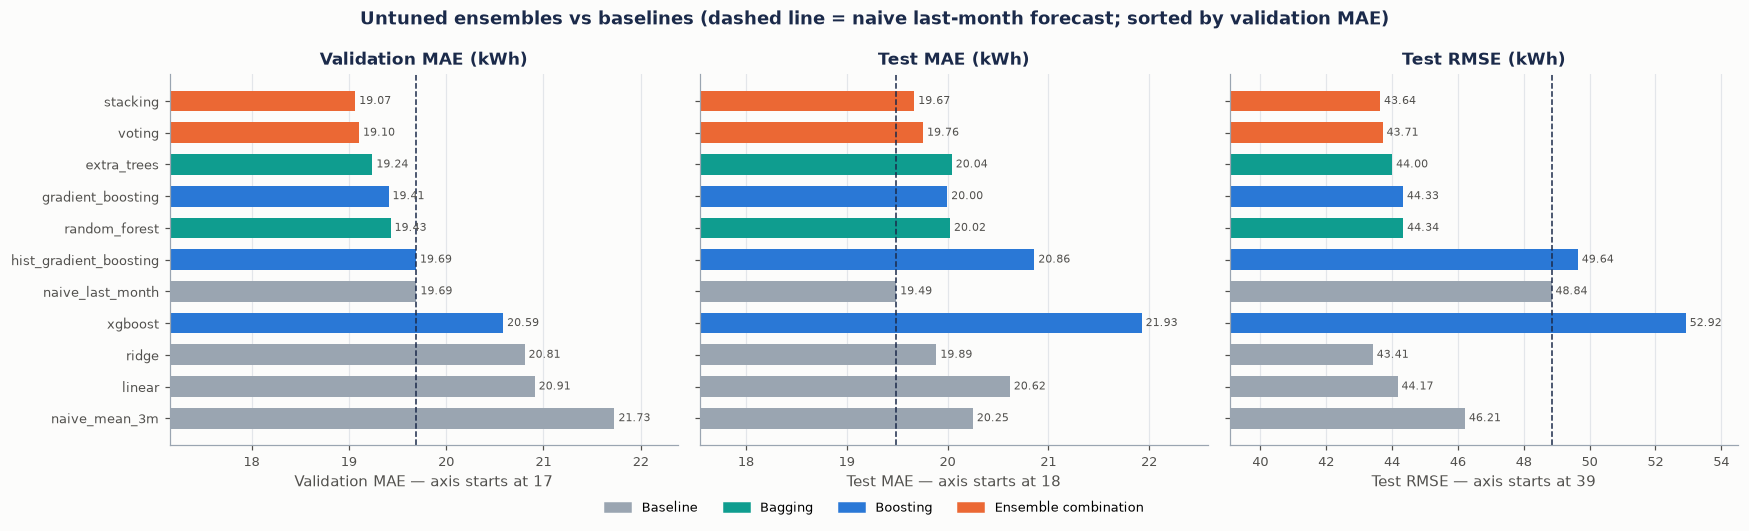

In [4]:
t = table.drop(index="dummy_mean")
fam_col = {"Baseline": ps.MUTED, "Bagging": ps.TEAL, "Boosting": ps.BLUE, "Ensemble combination": ps.ORANGE}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, m, ttl in [(ax[0], "cv_MAE", "Validation MAE"), (ax[1], "test_MAE", "Test MAE"), (ax[2], "test_RMSE", "Test RMSE")]:
    a.barh(t.index, t[m], color=[fam_col[f] for f in t.family], height=0.65)
    a.axvline(t.loc["naive_last_month", m], color=ps.NAVY, ls="--", lw=1)
    lo = t[m].min() * 0.9; a.set_xlim(lo, t[m].max() * 1.03)
    for i, v in enumerate(t[m]): a.text(v, i, f" {v:.2f}", va="center", fontsize=7.5, color=ps.INK_2)
    a.set(title=f"{ttl} ({U})", xlabel=f"{ttl} — axis starts at {lo:.0f}"); a.grid(axis="y", visible=False)
ax[0].invert_yaxis()
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_col.values()]
fig.legend(handles, fam_col.keys(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Untuned ensembles vs baselines (dashed line = naive last-month forecast; sorted by validation MAE)", color=ps.NAVY, fontweight="bold")
plt.tight_layout(); plt.show()

_Note: the x-axes do not start at zero, to make small differences visible; read the printed values._

**Observation (untuned).**

* **Validation MAE:** the two combination methods are best — Stacking 19.07 and Voting 19.10 kWh — followed by Extra
  Trees 19.24, Gradient Boosting 19.41 and Random Forest 19.43. All five beat the naive forecast (19.70), but only by
  0.3–0.6 kWh (≈ 2–3%).
* **Test MAE:** no untuned ensemble beats the naive forecast on MAE (19.49): Stacking 19.67, Voting 19.76, the single
  ensembles ≈ 20.0 kWh.
* **RMSE tells a different story:** all good ensembles reduce RMSE clearly — test RMSE 43.6–44.3 kWh vs 48.8 for the
  naive forecast (≈ 10% lower) — i.e. they make far fewer *large* mistakes. Ridge is equally good on test RMSE (43.4).
* **Untuned XGBoost and HistGradientBoosting are worse than the naive forecast** (test RMSE 52.9 and 49.6): their
  defaults (XGBoost: depth 6, learning rate 0.3) fit too aggressively for this noisy target — they need tuning.

**Why do ensembles improve RMSE far more than MAE?** All of these models are trained to minimise **squared error**. That
objective rewards fixing the big misses (households changing level) — exactly what RMSE measures — and pays little
attention to the many small errors of stable households, which dominate MAE. Because MAE is our selection metric, the
**loss function itself** is tuned in notebook 06 (absolute-error / Huber loss, log target), not just tree settings.

## 3. Over-fitting check — training vs validation error

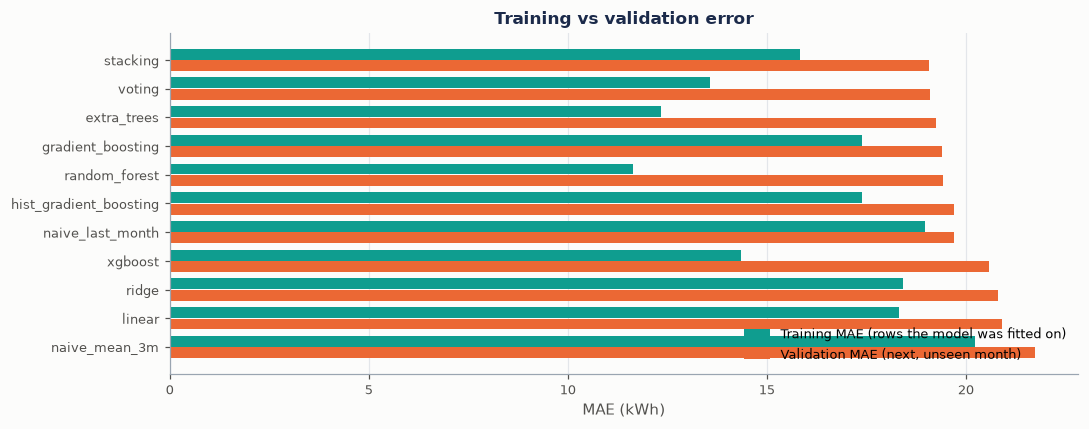

,train_MAE,cv_MAE,gap
label,,,
random_forest,11.63,19.43,7.80
extra_trees,12.34,19.24,6.90
xgboost,14.35,20.59,6.24
voting,13.57,19.10,5.54
stacking,15.83,19.07,3.24
linear,18.32,20.91,2.59
ridge,18.41,20.81,2.40
hist_gradient_boosting,17.40,19.69,2.29
gradient_boosting,17.40,19.41,2.01


In [5]:
o = table.drop(index=["dummy_mean"])[["train_MAE", "cv_MAE"]]
o["gap"] = o.cv_MAE - o.train_MAE
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(o))
ax.barh(y - 0.2, o.train_MAE, height=0.38, color=ps.TEAL, label="Training MAE (rows the model was fitted on)")
ax.barh(y + 0.2, o.cv_MAE, height=0.38, color=ps.ORANGE, label="Validation MAE (next, unseen month)")
ax.set_yticks(y); ax.set_yticklabels(o.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(title="Training vs validation error", xlabel=f"MAE ({U})"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
o.round(2).sort_values("gap", ascending=False)

**Observation.** The forests fit their training rows much more closely than unseen months (Random Forest: training MAE
11.6 vs validation 19.4 kWh; gap 7.8). This is normal for bagging — deep trees memorise training households, and
averaging keeps validation error low — but the size of the gap suggests the forests could generalise better with larger
leaves or shallower trees (tested in notebook 06). Gradient Boosting (gap 2.0) and the linear models (≈ 2.5) barely
over-fit. Stacking has a smaller gap (3.2) than Voting (5.5) because its meta-learner gives weight to the naive and
Ridge predictions, which do not memorise.

## 4. Fold-by-fold validation error

In [6]:
labels = ["naive_last_month", "ridge", "extra_trees", "gradient_boosting", "voting", "stacking"]
cvs = pd.concat([load_cv(("main" if l in ("naive_last_month", "ridge") else "untuned"), l).assign(label=l) for l in labels])
piv = cvs.pivot(index="validation_month", columns="label", values="val_MAE")[labels]
piv.round(2)

label,naive_last_month,ridge,extra_trees,gradient_boosting,voting,stacking
validation_month,,,,,,
2024-01,17.15,17.73,16.58,16.41,16.34,16.12
2024-02,17.33,17.67,17.01,16.51,16.60,16.40
2024-03,20.10,21.01,19.85,20.19,19.94,19.65
2024-04,23.02,26.35,22.08,23.08,22.25,21.32
2024-05,20.88,21.28,20.68,20.84,20.39,21.83


**Observation.** The ranking is consistent across folds: Stacking or Voting has the lowest error in 4 of the 5
validation months, and every ensemble beats the naive forecast in January–April 2024. April 2024 is the hardest month
for every model (naive 23.0 kWh); the stack reduces it most (21.3). In May 2024 the stack is worse than the naive
forecast (21.8 vs 20.9) — a reminder that gains of this size vary from month to month, so conclusions should rest on
all folds together, not a single month.

## 5. Time-ordered stacking — how it works here

```
Training months:  Jan 2023 ................................. Oct 2023 | Nov 2023 | Dec 2023 | ... | May 2024
                                                                  ↓          ↓                     ↓
For each month v from Nov 2023 to May 2024:
    base models (naive, Ridge, Extra Trees, Gradient Boosting) are trained ONLY on months before v
    and predict month v   →   "out-of-fold" (OOF) predictions: honest predictions of an unseen future month
Meta-learner (Ridge, non-negative weights):  bill ≈ w1·naive + w2·ridge + w3·extra_trees + w4·gradient_boosting + b
    learned from the ~28,000 OOF rows (Nov 2023 – May 2024)
Finally: base models are re-trained on the whole training period; at test time their predictions are combined with w.
```

**Why not sklearn's `StackingRegressor`?** It creates the OOF predictions with ordinary K-fold cross-validation, so a
base model trained on e.g. March 2024 would produce the "OOF" prediction for January 2024 — information from the future.
The meta-learner would then learn from predictions that are better than anything possible in real forecasting, and
would over-trust the base models. The time-ordered version only ever predicts forward in time.

**Validating the stack fairly:** for validation month *v* the stack uses base models trained on months < *v* and a
meta-learner trained only on OOF months < *v*. (In the January 2024 fold the meta-learner has only Nov–Dec 2023 to learn
from.)

In [7]:
import joblib  # noqa
bases = {"naive_last_month": make_pipeline("naive_last_month"), "ridge": make_pipeline("ridge", params={"alpha": 1000}),
         "extra_trees": make_pipeline("extra_trees"), "gradient_boosting": make_pipeline("gradient_boosting")}
# Fit only the meta-learner part again is not possible without base OOF predictions, so the weights are re-estimated
# here from a fresh fit (deterministic: same seeds) — this takes ~3 minutes.
from src.preprocessing import model_input_columns
stack = TimeOrderedStackingRegressor(bases)
cols = model_input_columns("history_only")
stack.fit(train[cols], train.consumption.to_numpy(), train.month.to_numpy())
w = stack.meta_weights_
print("Meta-learner weights:"); display(w.round(3).to_frame("weight").T)
oof = stack.oof_
corr = oof[list(bases)].corr()
print("Correlation between base-model OOF predictions (diversity check):"); corr.round(3)

Meta-learner weights:


,naive_last_month,ridge,extra_trees,gradient_boosting,intercept
weight,0.156,0.031,0.438,0.41,-0.538


Correlation between base-model OOF predictions (diversity check):


,naive_last_month,ridge,extra_trees,gradient_boosting
naive_last_month,1.000,0.981,0.976,0.975
ridge,0.981,1.000,0.991,0.991
extra_trees,0.976,0.991,1.000,0.995
gradient_boosting,0.975,0.991,0.995,1.000


**Observation.** The meta-learner gives Extra Trees (0.44) and Gradient Boosting (0.41) most of the weight, keeps some
weight on naive persistence (0.16), and almost none on Ridge (0.03). The weights sum to ≈ 1.04 with a near-zero
intercept, so the stack is essentially a **learned weighted average**.

**Diversity is limited:** the base models' OOF predictions are correlated 0.975–0.995. All of them rely mainly on the
same household history, so they make similar mistakes. This explains why stacking/voting improve only slightly on the
best single model — a combination can only help where its members disagree. This is an honest, expected finding for
a problem dominated by one very strong signal (last month's bill).

## 6. Summary

| Model (untuned) | Family | Validation MAE | Test MAE | Test RMSE | Test R² |
|---|---|---|---|---|---|
| Stacking (time-ordered) | Combination | **19.07** | 19.67 | 43.64 | 0.889 |
| Voting (RF + ET + GB) | Combination | 19.10 | 19.76 | 43.71 | 0.889 |
| Extra Trees | Bagging | 19.24 | 20.04 | 44.00 | 0.887 |
| Gradient Boosting | Boosting | 19.41 | 20.00 | 44.33 | 0.886 |
| Random Forest | Bagging | 19.43 | 20.02 | 44.34 | 0.886 |
| HistGradientBoosting | Boosting | 19.69 | 20.86 | 49.64 | 0.857 |
| XGBoost | Boosting | 20.59 | 21.93 | 52.92 | 0.837 |
| *Naive: last month* | *Baseline* | *19.70* | ***19.49*** | *48.84* | *0.861* |
| *Ridge* | *Baseline* | *20.81* | *19.89* | ***43.41*** | ***0.890*** |

(kWh per household-month.) Untuned ensembles beat the baselines on validation MAE and the naive forecast on RMSE, but
the margins are small, and on the test period the naive forecast still has the lowest MAE. notebook 06 tunes the models —
including their loss function — using the validation folds only.